# Prédiction du churn – Exploration et modélisation

**Projet fil rouge MLOps – Joe MAGNAN – MDSIA 2**

Cas d'étude : un opérateur télécom veut repérer les clients susceptibles de résilier (*churn*) pour leur proposer une action de rétention avant leur départ.

- **Variable cible** : `churn` (1 = le client résilie, 0 = il reste)
- **Type de problème** : classification binaire supervisée
- **Données** : 2 000 clients générés par `src/generate_data.py` (graine 42)

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_csv(ROOT / 'data' / 'raw' / 'churn.csv')
sns.set_theme(style='whitegrid')
df.head()

,age,anciennete,revenu,nb_reclamations,montant_mensuel,retards_paiement,churn
0,56,93,407324,2,35104,3,0
1,69,64,869449,0,42594,1,0
2,46,44,904651,3,8664,2,0
3,32,53,808681,4,15528,2,0
4,60,24,580599,4,33190,1,1


## 1. Qualité des données

In [2]:
print('Dimensions :', df.shape)
print('\nTypes :'); print(df.dtypes)
print('\nValeurs manquantes :', int(df.isnull().sum().sum()))
print('Doublons :', int(df.duplicated().sum()))

Dimensions : (2000, 7)

Types :
age                 int64
anciennete          int64
revenu              int64
nb_reclamations     int64
montant_mensuel     int64
retards_paiement    int64
churn               int64
dtype: object

Valeurs manquantes : 0
Doublons : 0


In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,2000.0,43.8,14.9,18.0,31.0,44.0,56.0,69.0
anciennete,2000.0,58.8,34.8,1.0,28.0,58.0,89.0,119.0
revenu,2000.0,583363.9,244511.5,150159.0,372126.8,580185.5,797360.2,999776.0
nb_reclamations,2000.0,1.9,1.3,0.0,1.0,2.0,3.0,8.0
montant_mensuel,2000.0,38699.9,20235.3,5005.0,21335.5,38165.5,56366.5,74963.0
retards_paiement,2000.0,1.0,1.0,0.0,0.0,1.0,2.0,6.0
churn,2000.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0


Aucune valeur manquante ni doublon : pas d'imputation nécessaire. Les variables sont toutes numériques mais sur des échelles très différentes (revenu en centaines de milliers de FCFA, réclamations entre 0 et 10) : la régression logistique aura besoin d'une standardisation.

## 2. Répartition de la cible

churn
0    1139
1     861
Name: count, dtype: int64
Taux de churn : 43.0%


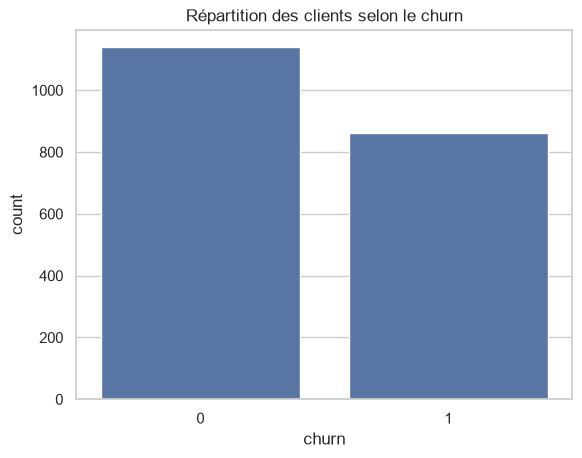

In [4]:
print(df['churn'].value_counts())
print(f"Taux de churn : {df['churn'].mean():.1%}")
ax = sns.countplot(data=df, x='churn')
ax.set_title('Répartition des clients selon le churn');

Les classes sont **modérément déséquilibrées** (43 % / 57 %) : l'accuracy seule suffirait presque, mais on suivra aussi la précision, le rappel, le F1 et le ROC-AUC, et le découpage train/test sera **stratifié** pour garder la même proportion de churn dans les deux jeux.

## 3. Corrélations

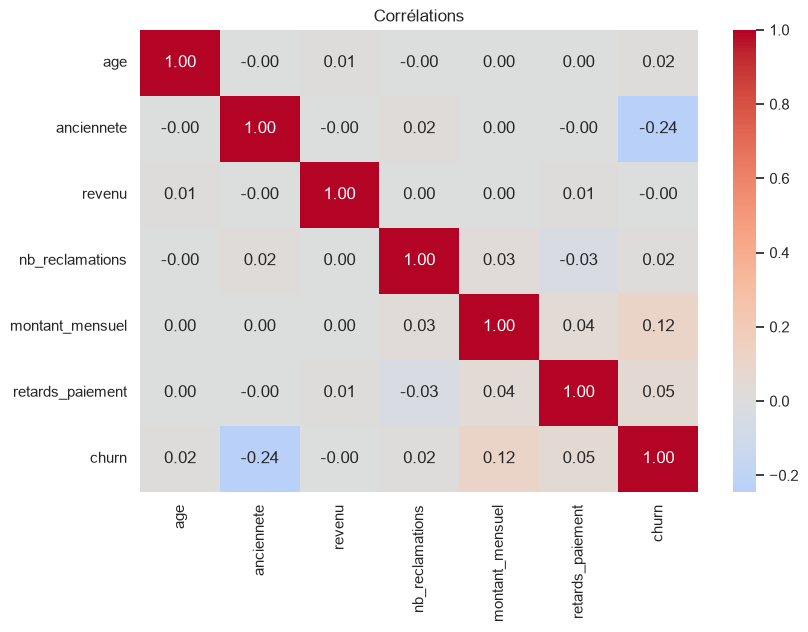

In [5]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Corrélations');

In [6]:
df.corr()['churn'].drop('churn').sort_values()

anciennete         -0.244608
revenu             -0.000511
nb_reclamations     0.015528
age                 0.016201
retards_paiement    0.049860
montant_mensuel     0.115945
Name: churn, dtype: float64

L'**ancienneté** est de loin la variable la plus liée au churn (corrélation d'environ −0,25 : les clients récents partent davantage), suivie du **montant mensuel** (+0,12) et, plus faiblement, des **retards de paiement** (+0,05). L'âge et le revenu ne sont pas corrélés au churn, ce qui est cohérent avec le générateur (ils n'entrent pas dans le score). Les **réclamations** ont un effet si faible (coefficient 0,04 dans le générateur) qu'il est invisible sur 2 000 clients (corrélation 0,02, comme l'âge) : le sujet laisse entendre qu'elles comptent, mais les données ne le montrent pas.

## 4. Churn selon l'ancienneté et distributions par classe

anciennete
0-12      0.668
13-24     0.596
25-48     0.487
49-72     0.387
73-120    0.306
Name: churn, dtype: float64

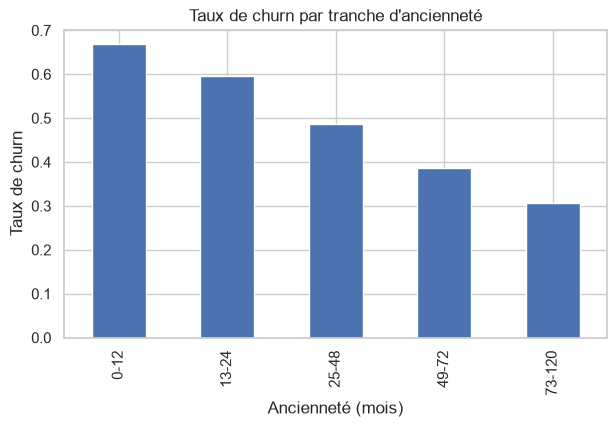

In [7]:
tranches = pd.cut(df['anciennete'], bins=[0, 12, 24, 48, 72, 120],
                  labels=['0-12', '13-24', '25-48', '49-72', '73-120'])
taux = df.groupby(tranches, observed=True)['churn'].mean()
ax = taux.plot(kind='bar', color='#4C72B0', figsize=(7, 4))
ax.set_ylabel('Taux de churn'); ax.set_xlabel('Ancienneté (mois)')
ax.set_title("Taux de churn par tranche d'ancienneté")
taux.round(3)

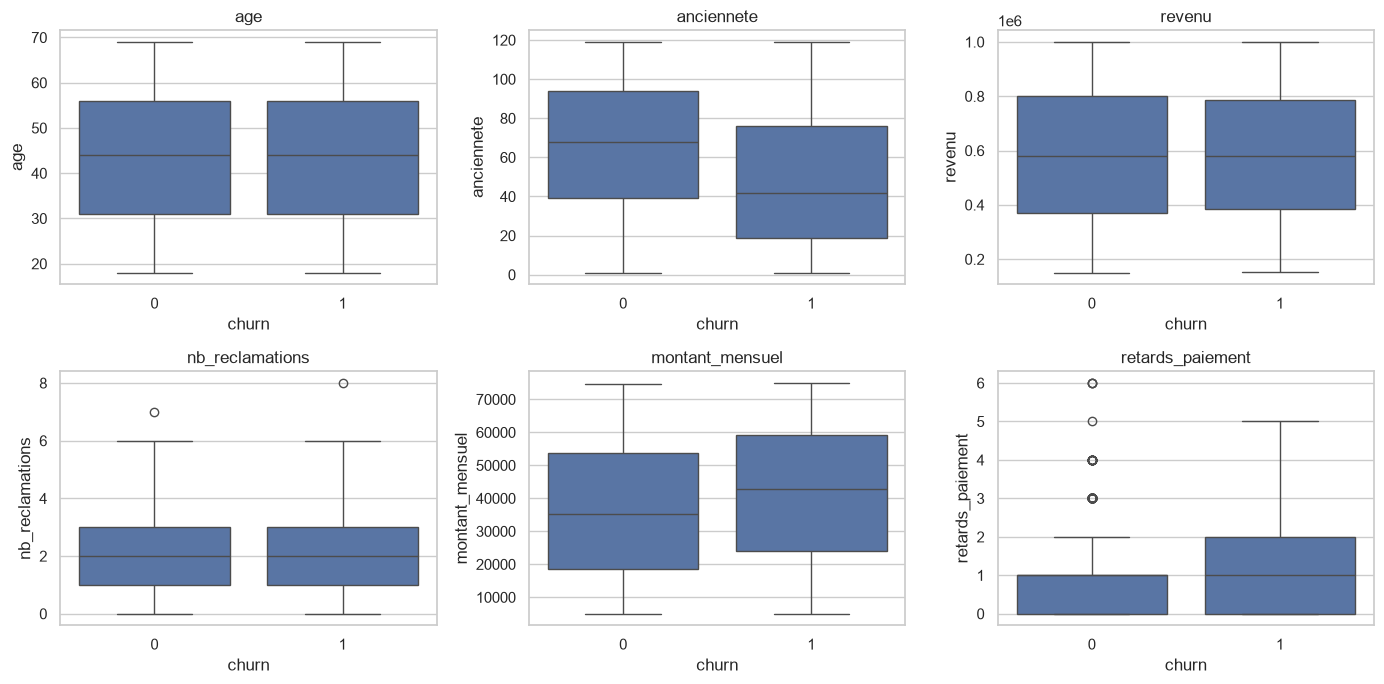

In [8]:
features = [c for c in df.columns if c != 'churn']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x='churn', y=col, ax=ax)
    ax.set_title(col)
fig.tight_layout()

Le signal est **réel mais faible** : les distributions se recouvrent largement. Même un bon modèle ne pourra pas dépasser un ROC-AUC d'environ 0,65–0,70, car le churn est tiré au hasard à partir d'une probabilité comprise entre 20 % et 70 %. Les performances attendues sont donc modestes, et la probabilité de 0,87 donnée en exemple dans le sujet est irréaliste sur ces données.

## 5. Comparaison des modèles

`src/train.py` compare les trois modèles du sujet avec une **validation croisée stratifiée à 5 plis** sur le jeu d'entraînement (80 %), puis évalue le modèle retenu sur le jeu de test (20 %), jamais utilisé pour choisir le modèle.

In [9]:
report = json.loads((ROOT / 'reports' / 'metrics.json').read_text(encoding='utf-8'))
rows = []
for name, r in report['results'].items():
    rows.append({'modèle': name, **{f'cv_{k}': v for k, v in r['cv'].items()},
                 **{f'test_{k}': v for k, v in r['test'].items() if k != 'confusion_matrix'}})
comparison = pd.DataFrame(rows).set_index('modèle')
print('Modèle retenu :', report['selected_model'], '—', report['selection_reason'])
comparison

Modèle retenu : logistic_regression — meilleur f1 moyen en validation croisée 5 plis (0.5231)


,cv_f1,cv_roc_auc,cv_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
modèle,,,,,,,,
logistic_regression,0.5231,0.6551,0.6319,0.6250,0.5821,0.4535,0.5098,0.6364
decision_tree,0.4357,0.6235,0.6275,0.6325,0.5828,0.5116,0.5449,0.6233
random_forest,0.4875,0.6216,0.6100,0.6025,0.5474,0.4360,0.4854,0.6247


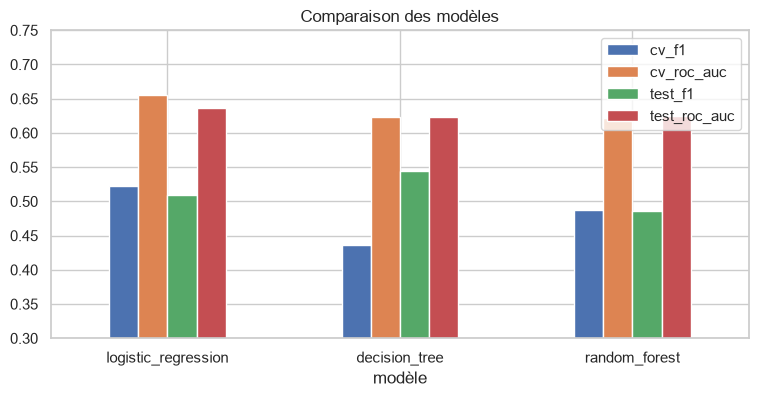

In [10]:
ax = comparison[['cv_f1', 'cv_roc_auc', 'test_f1', 'test_roc_auc']].plot(kind='bar', figsize=(9, 4))
ax.set_ylim(0.3, 0.75); ax.set_title('Comparaison des modèles'); plt.xticks(rotation=0);

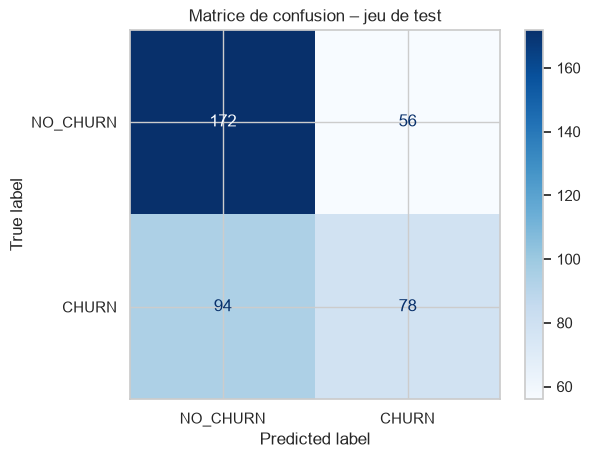

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
cm = np.array(report['results'][report['selected_model']]['test']['confusion_matrix'])
ConfusionMatrixDisplay(cm, display_labels=['NO_CHURN', 'CHURN']).plot(cmap='Blues')
plt.title('Matrice de confusion – jeu de test');

## 6. Conclusions

- La **régression logistique** obtient le meilleur F1 et le meilleur ROC-AUC en validation croisée. C'est logique : le générateur du sujet est lui-même une fonction logistique (linéaire dans le logit) des variables, exactement la forme que ce modèle suppose.
- Le **Random Forest**, imposé par le sujet, est légèrement moins bon et bien plus lourd (200 arbres contre 7 coefficients) : il est plus lent en production et n'apporte rien ici. On peut toutefois le forcer avec `python src/train.py --model random_forest`.
- L'**arbre de décision** a le meilleur F1 *sur le jeu de test*, mais le plus faible en validation croisée : c'est un effet du hasard sur 400 clients. C'est précisément pour cela que la sélection se fait en validation croisée et non sur le jeu de test.
- Le seuil de décision vaut 0,5. En production, il devrait être choisi selon le coût d'une action de rétention comparé à celui d'un client perdu (privilégier le rappel si perdre un client coûte cher).